<h2 style="color:rgb(0,120,170)">Runtime vs obstacle count</h2>

**Question:** how does the full runtime grow when the map gets more and more crowded?

**Setup:** a larger 40 × 40 map with 50, 80, 120, 160 and 200 small obstacles (one map per count), start (2, 2), goal (38, 38). The maps are made with `generate_dense_scaling_map` from `utils/maps_generation_utils.py`: obstacles don't overlap and don't cover start or goal.

In [8]:
from utils.compare_tables_util import relabel_tables, show_benchmark_tables
from utils.maps_generation_utils import generate_dense_scaling_map
from utils.path_planning_utils import benchmark_batches
from utils.plot_utils import plot, plot_algorithm_graph_big_data_comparison

### Settings

In [9]:
OBSTACLE_COUNTS = [50, 80, 120, 160, 200]
MAP_SIZE = 40
START_DENSE = (2, 2)
END_DENSE = (38, 38)
RUNTIME_RUNS = 1
RRT_KWARGS = {"iterations": 2500, "gamma": 4.0, "goal_sample_rate": 0.2}
PRM_KWARGS = {"rand_area": (0, MAP_SIZE), "n_samples": 300, "k": 10, "max_edge_len": 8.0}

### Maps
Each map has its own seed (1000 + obstacle count), so the maps are the same every run.

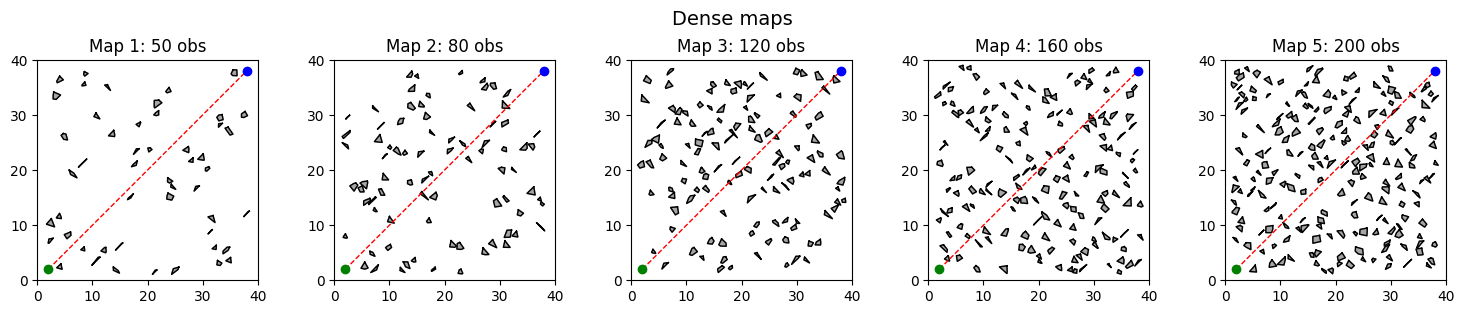

In [10]:
dense_batches = [
    [generate_dense_scaling_map(count, map_size=MAP_SIZE, start=START_DENSE, end=END_DENSE, seed=1000 + count)]
    for count in OBSTACLE_COUNTS
]
dense_labels = [f"obs_{count}" for count in OBSTACLE_COUNTS]

plot(
    [batch[0] for batch in dense_batches],
    "Dense maps",
    map_size=MAP_SIZE,
    cols=len(dense_batches),
    start=START_DENSE,
    end=END_DENSE,
    show_line=True,
)

### Run the benchmark

In [11]:
dense_scaling_tables = benchmark_batches(
    dense_batches,
    START_DENSE,
    END_DENSE,
    rrt_kwargs=RRT_KWARGS,
    prm_kwargs=PRM_KWARGS,
    include_algorithm_setup=True,
    runtime_runs=RUNTIME_RUNS,
)
dense_scaling_tables = relabel_tables(dense_scaling_tables, dense_labels)

### Results
Runtime in seconds. Columns are obstacle counts.

In [12]:
show_benchmark_tables("Dense scaling", dense_scaling_tables)

### Dense scaling: VG

| map | obs_50 | obs_80 | obs_120 | obs_160 | obs_200 |
| --- | --- | --- | --- | --- | --- |
| map_1 | 0.376322 | 1.019794 | 2.670974 | 4.833523 | 7.912049 |

### Dense scaling: VG summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| obs_50 | 100.0% | 0.376322 | 0.376322 | 0.376322 | 0.376322 | 1/1 |
| obs_80 | 100.0% | 1.019794 | 1.019794 | 1.019794 | 1.019794 | 1/1 |
| obs_120 | 100.0% | 2.670974 | 2.670974 | 2.670974 | 2.670974 | 1/1 |
| obs_160 | 100.0% | 4.833523 | 4.833523 | 4.833523 | 4.833523 | 1/1 |
| obs_200 | 100.0% | 7.912049 | 7.912049 | 7.912049 | 7.912049 | 1/1 |

Overall:
- success_rate: 100.0%
- median: 2.670974
- mean: 3.362533
- min: 0.376322
- max: 7.912049
- valid: 5/5

### Dense scaling: RRT_star

| map | obs_50 | obs_80 | obs_120 | obs_160 | obs_200 |
| --- | --- | --- | --- | --- | --- |
| map_1 | 0.059825 | 0.117716 | 0.134405 | 0.188294 | 0.196124 |

### Dense scaling: RRT_star summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| obs_50 | 100.0% | 0.059825 | 0.059825 | 0.059825 | 0.059825 | 1/1 |
| obs_80 | 100.0% | 0.117716 | 0.117716 | 0.117716 | 0.117716 | 1/1 |
| obs_120 | 100.0% | 0.134405 | 0.134405 | 0.134405 | 0.134405 | 1/1 |
| obs_160 | 100.0% | 0.188294 | 0.188294 | 0.188294 | 0.188294 | 1/1 |
| obs_200 | 100.0% | 0.196124 | 0.196124 | 0.196124 | 0.196124 | 1/1 |

Overall:
- success_rate: 100.0%
- median: 0.134405
- mean: 0.139273
- min: 0.059825
- max: 0.196124
- valid: 5/5

### Dense scaling: PRM

| map | obs_50 | obs_80 | obs_120 | obs_160 | obs_200 |
| --- | --- | --- | --- | --- | --- |
| map_1 | 0.205931 | 0.326737 | 0.472341 | 0.631095 | 0.758525 |

### Dense scaling: PRM summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| obs_50 | 100.0% | 0.205931 | 0.205931 | 0.205931 | 0.205931 | 1/1 |
| obs_80 | 100.0% | 0.326737 | 0.326737 | 0.326737 | 0.326737 | 1/1 |
| obs_120 | 100.0% | 0.472341 | 0.472341 | 0.472341 | 0.472341 | 1/1 |
| obs_160 | 100.0% | 0.631095 | 0.631095 | 0.631095 | 0.631095 | 1/1 |
| obs_200 | 100.0% | 0.758525 | 0.758525 | 0.758525 | 0.758525 | 1/1 |

Overall:
- success_rate: 100.0%
- median: 0.472341
- mean: 0.478926
- min: 0.205931
- max: 0.758525
- valid: 5/5

### Runtime vs obstacle count

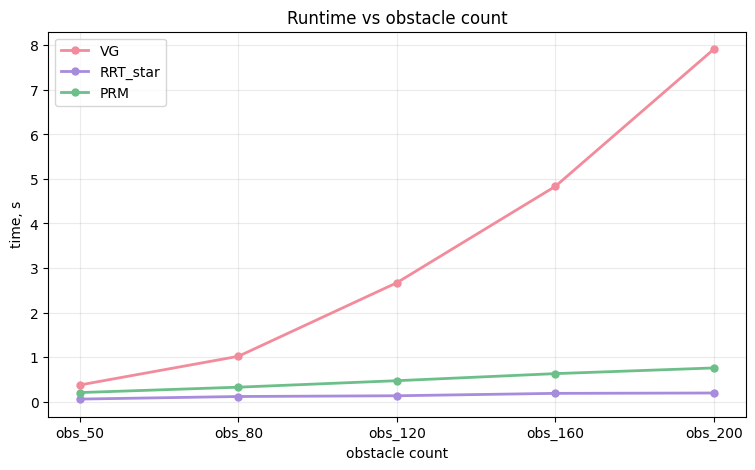

In [13]:
plot_algorithm_graph_big_data_comparison(
    dense_scaling_tables,
    title="Runtime vs obstacle count",
    ylabel="time, s",
);

**Result:** We notice a clear linear runtime growth for **PRM** and **RRT\***, **VG** exhibits a non-linear growth